***Homemade linear regression***

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

class LinearRegression:
    def __init__(self):
        self.coefficient = None
        self.intercept = None
        self.columns = None

    def fit(self, X, y):
        X = pd.DataFrame(X) 
        y=np.asarray(y, dtype=float).flatten()

        # To create intercept column in design matrix
        X.insert(0, "intercept", 1.0)
        # Converts true/false to 1/0 and text columns become dummy as well.
        X = pd.get_dummies(X, drop_first=True)
        X_b = X.to_numpy(dtype=float)

        beta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept = beta[0]
        self.coefficient = beta[1:]
        self.columns = X.columns[1:]
       
    def predict(self, X):
        X = pd.DataFrame(X) 
        X = pd.get_dummies(X, drop_first=False)
        X = X.reindex(columns=self.columns, fill_value=0)
        return X.to_numpy(dtype=float).dot(self.coefficient) + self.intercept

    def score(self, X, y):
        y=np.asarray(y, dtype=float).flatten()
        y_pred = self.predict(X)  
        return 1 - np.sum((y - y_pred)**2) / np.sum((y - np.mean(y))**2)
    
    def mse(self, X, y):
        y = np.asarray(y, dtype=float).flatten()
        y_pred = self.predict(X)
        return np.mean((y - y_pred) ** 2)
    
    def rss(self, X, y):
        y = np.asarray(y, dtype=float).flatten()
        y_pred = self.predict(X)
        return np.sum((y - y_pred) ** 2)

    def summary(self):
        if self.coefficient is None:
            raise ValueError("Model is not fitted yet.")

        terms = [f"{self.intercept:.3f}"]
        for name, coef in zip(self.columns, self.coefficient):
            sign = "-" if coef < 0 else "+"
            terms.append(f"{sign} {abs(coef):.3f}*{name}")

        print("y = " + " ".join(terms))



Simplify df and convert rotation

In [13]:
import pandas as pd
train=pd.read_csv("MLProject2026/data/case1/train1.csv")
test=pd.read_csv("MLProject2026/data/case1/test1.csv")

for df in (train, test):
    df["n"] = df["speed_rpm"] / 1000
    df["Q"] = df["flow_m3_h"]
    df["P"] = df["power_w"]

train=train[["n", "Q","P"]]
test=test[["n", "Q","P"]]


FileNotFoundError: [Errno 2] No such file or directory: 'MLProject2026/data/case1/train1.csv'

Creating all combinations as seen in function 
$P=\sum_{i=0}^3\sum_{j=0}^3\alpha_{ij}n^iQ^j$

In [ ]:
def make_features(df):
    features = pd.DataFrame()

    for i in range(4):
        for j in range(4):
            if i == 0 and j == 0:
                continue        

            column_name = "n" + str(i) + "Q" + str(j)
            features[column_name] = df["n"] ** i * df["Q"] ** j

    return features


X_train = make_features(train)
y_train = train["P"]

X_test = make_features(test)
y_test = test["P"]

y_train

0       669.992714
1       931.528480
2       724.198083
3        99.463217
4       608.195308
          ...     
475     815.229829
476     515.961500
477     534.173942
478     154.677482
479    1765.102052
Name: P, Length: 480, dtype: float64

Create folds and compute linear regression plus MSE. 

In [ ]:
import random
def make_folds(n_rows, k, seed=30):
    random.seed(seed)
    n = int(n_rows / k)
    li = list(range(n_rows))
    lis_id = [[] for _ in range(k)]

    for i in range(k):
        for j in range(n):
            my_id = random.choice(li)
            lis_id[i].append(my_id)
            li.remove(my_id)
    return lis_id

def kfold(X, y, cols, folds):
    error = []
    for i in range(len(folds)):
        x_out = X[cols].iloc[folds[i]]
        y_out = y.iloc[folds[i]].to_numpy()
        x_train = X[cols].drop(X.index[folds[i]])
        y_train = y.drop(y.index[folds[i]])

        model = LinearRegression()
        model.fit(x_train, y_train)

        error.append(model.mse(x_out, y_out))

    return np.array(error)

Create every subset of feaures and fit all models over it. 

In [ ]:
folds = make_folds(len(X_train), k=5)
all_cols = list(X_train.columns)


all_subsets = [[]]
for col in all_cols:
    new_subsets = []
    for subset in all_subsets:
        new_subsets.append(subset + [col])
    all_subsets = all_subsets + new_subsets
all_subsets = all_subsets[1:]

# Step 2: evaluate every subset with 5-fold CV
results = []
for subset in all_subsets:
    e = kfold(X_train, y_train, subset, folds)
    results.append({"n_terms": len(subset), "features": tuple(subset),
                    "mse": e.mean(), "se": e.std(ddof=1) / np.sqrt(len(e))})

results = pd.DataFrame(results)


32767


In [ ]:
all_subsets

[['n0Q1'],
 ['n0Q2'],
 ['n0Q1', 'n0Q2'],
 ['n0Q3'],
 ['n0Q1', 'n0Q3'],
 ['n0Q2', 'n0Q3'],
 ['n0Q1', 'n0Q2', 'n0Q3'],
 ['n1Q0'],
 ['n0Q1', 'n1Q0'],
 ['n0Q2', 'n1Q0'],
 ['n0Q1', 'n0Q2', 'n1Q0'],
 ['n0Q3', 'n1Q0'],
 ['n0Q1', 'n0Q3', 'n1Q0'],
 ['n0Q2', 'n0Q3', 'n1Q0'],
 ['n0Q1', 'n0Q2', 'n0Q3', 'n1Q0'],
 ['n1Q1'],
 ['n0Q1', 'n1Q1'],
 ['n0Q2', 'n1Q1'],
 ['n0Q1', 'n0Q2', 'n1Q1'],
 ['n0Q3', 'n1Q1'],
 ['n0Q1', 'n0Q3', 'n1Q1'],
 ['n0Q2', 'n0Q3', 'n1Q1'],
 ['n0Q1', 'n0Q2', 'n0Q3', 'n1Q1'],
 ['n1Q0', 'n1Q1'],
 ['n0Q1', 'n1Q0', 'n1Q1'],
 ['n0Q2', 'n1Q0', 'n1Q1'],
 ['n0Q1', 'n0Q2', 'n1Q0', 'n1Q1'],
 ['n0Q3', 'n1Q0', 'n1Q1'],
 ['n0Q1', 'n0Q3', 'n1Q0', 'n1Q1'],
 ['n0Q2', 'n0Q3', 'n1Q0', 'n1Q1'],
 ['n0Q1', 'n0Q2', 'n0Q3', 'n1Q0', 'n1Q1'],
 ['n1Q2'],
 ['n0Q1', 'n1Q2'],
 ['n0Q2', 'n1Q2'],
 ['n0Q1', 'n0Q2', 'n1Q2'],
 ['n0Q3', 'n1Q2'],
 ['n0Q1', 'n0Q3', 'n1Q2'],
 ['n0Q2', 'n0Q3', 'n1Q2'],
 ['n0Q1', 'n0Q2', 'n0Q3', 'n1Q2'],
 ['n1Q0', 'n1Q2'],
 ['n0Q1', 'n1Q0', 'n1Q2'],
 ['n0Q2', 'n1Q0', 'n1Q2'],
 ['n0Q1', 

Choosing the best subset for each number of terms

In [ ]:
# Step 1: best subset for each number of terms
best_rows = []
for t in range(1, len(all_cols) + 1):
    models_with_t_terms = results[results["n_terms"] == t]
    best_model = models_with_t_terms.sort_values("mse").iloc[0]
    best_rows.append(best_model)
best = pd.DataFrame(best_rows).reset_index(drop=True)
best.sort_values("mse")

,n_terms,features,mse,se
6,7,"(n0Q3, n1Q2, n1Q3, n2Q1, n2Q3, n3Q0, n3Q3)",112.827460,13.405972
5,6,"(n0Q2, n0Q3, n2Q1, n2Q2, n3Q0, n3Q2)",112.856648,13.185157
3,4,"(n0Q3, n1Q2, n2Q1, n3Q0)",113.034769,12.681345
4,5,"(n0Q1, n0Q3, n1Q2, n2Q1, n3Q0)",113.223608,12.864574
7,8,"(n0Q1, n0Q2, n0Q3, n1Q2, n2Q1, n2Q3, n3Q0, n3Q3)",113.326632,13.022893
8,9,"(n0Q1, n0Q3, n1Q0, n1Q1, n1Q2, n2Q0, n2Q1, n3Q...",113.675096,13.156938
9,10,"(n0Q1, n0Q3, n1Q0, n1Q2, n1Q3, n2Q0, n2Q1, n2Q...",114.265405,13.830289
11,12,"(n0Q1, n0Q2, n0Q3, n1Q1, n1Q2, n1Q3, n2Q2, n2Q...",114.319355,14.005744
12,13,"(n0Q1, n0Q2, n0Q3, n1Q1, n1Q2, n1Q3, n2Q1, n2Q...",114.449704,13.897972
10,11,"(n0Q1, n0Q2, n0Q3, n1Q0, n1Q2, n1Q3, n2Q0, n2Q...",114.485731,13.792210


Using the the One-Standard-Error (1-SE) rule to choose the best combination of features. 

In [ ]:
lowest = best.sort_values("mse").iloc[0]
threshold = lowest["mse"] + lowest["se"]

# Step 3: smallest model below the threshold
for i in range(len(best)):
    if best.iloc[i]["mse"] <= threshold:
        chosen = best.iloc[i]
        break

print("Chosen:", chosen["n_terms"], "terms:", chosen["features"])

Chosen: 4 terms: ('n0Q3', 'n1Q2', 'n2Q1', 'n3Q0')


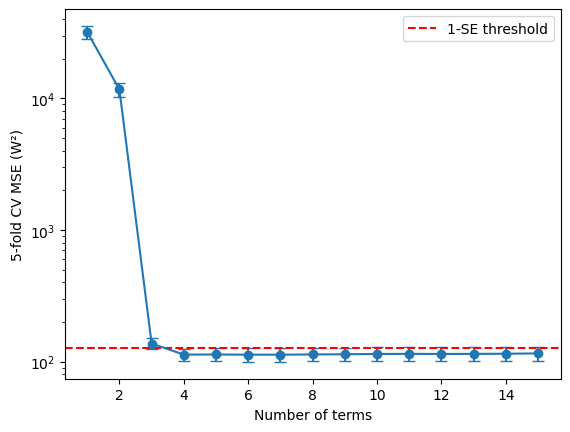

In [ ]:
plt.errorbar(best["n_terms"], best["mse"], yerr=best["se"], marker="o", capsize=4)
plt.axhline(threshold, color="red", linestyle="--", label="1-SE threshold")
plt.yscale("log")
plt.xlabel("Number of terms")
plt.ylabel("5-fold CV MSE (W²)")
plt.legend()
plt.show()

In [ ]:
chosen_cols = list(chosen["features"])      # ["n0Q3", "n1Q2", "n2Q1", "n3Q0"]

final_model = LinearRegression()
final_model.fit(X_train[chosen_cols], y_train)

y_pred = final_model.predict(X_test[chosen_cols])
residuals = y_test.to_numpy() - y_pred
test_r2   = final_model.score(X_test[chosen_cols], y_test)
print(f"R²:   {test_r2:.4f}")
final_model.summary()


R²:   0.9996
y = 40.865 - 0.008*n0Q3 - 0.050*n1Q2 + 2.407*n2Q1 + 7.658*n3Q0


In [9]:
plt.figure(figsize=(7, 4))
plt.scatter(test["Q"], residuals, c=test["n"], cmap="viridis", s=15)
plt.colorbar(label="n (krpm)")
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Flow Q (m³/h)")
plt.ylabel("Residual P − P̂ (W)")
plt.title("Test residuals vs. flow")
plt.tight_layout()
plt.show()

NameError: name 'test' is not defined

<Figure size 700x400 with 0 Axes>

Using BIC to check the choosen features

In [ ]:
N = len(X_train)
bic_results = []

for subset in all_subsets:
    model = LinearRegression()
    model.fit(X_train[subset], y_train)

    rss = model.rss(X_train[subset], y_train)
    p = len(subset) + 1                               # terms + intercept
    bic = N * np.log(rss / N) + p * np.log(N)

    bic_results.append({"n_terms": len(subset), "features": tuple(subset), "bic": bic})

bic_results = pd.DataFrame(bic_results)

Choosing the best subset for each number of terms

In [ ]:
bic_best_rows = []
for t in range(1, n_cols + 1):
    models_with_t_terms = bic_results[bic_results["n_terms"] == t]
    bic_best_rows.append(models_with_t_terms.sort_values("bic").iloc[0])
bic_best = pd.DataFrame(bic_best_rows).reset_index(drop=True)

print("Lowest BIC:", bic_best.sort_values("bic").iloc[0]["features"])

Lowest BIC: ('n0Q3', 'n1Q2', 'n2Q1', 'n3Q0')


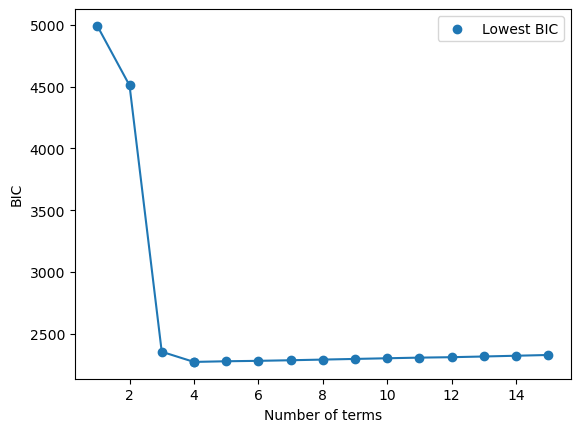

In [ ]:
best_bic_row = bic_best.sort_values("bic").iloc[0]

plt.plot(bic_best["n_terms"], bic_best["bic"], marker="o")
plt.scatter(best_bic_row["n_terms"], best_bic_row["bic"],  label="Lowest BIC")
plt.xlabel("Number of terms")
plt.ylabel("BIC")
plt.legend()
plt.show()

In [ ]:
N = len(X_train)
aic_results = []

for subset in all_subsets:
    model = LinearRegression()
    model.fit(X_train[subset], y_train)

    rss = model.rss(X_train[subset], y_train)
    p = len(subset) + 1                          # terms + intercept
    aic = N * np.log(rss / N) + 2 * p

    aic_results.append({"n_terms": len(subset), "features": tuple(subset), "aic": aic})

aic_results = pd.DataFrame(aic_results)

In [ ]:
aic_best_rows = []
for t in range(1, n_cols + 1):
    models_with_t_terms = aic_results[aic_results["n_terms"] == t]
    aic_best_rows.append(models_with_t_terms.sort_values("aic").iloc[0])
aic_best = pd.DataFrame(aic_best_rows).reset_index(drop=True)

print(aic_best[["n_terms", "aic", "features"]].to_string())
print("Lowest AIC:", aic_best.sort_values("aic").iloc[0]["features"])

    n_terms          aic                                                                                    features
0         1  4982.448739                                                                                     (n3Q0,)
1         2  4497.251346                                                                                (n2Q2, n3Q1)
2         3  2338.840060                                                                          (n0Q3, n2Q1, n3Q0)
3         4  2252.438008                                                                    (n0Q3, n1Q2, n2Q1, n3Q0)
4         5  2253.641398                                                              (n0Q3, n1Q0, n1Q2, n2Q1, n3Q0)
5         6  2252.840735                                                        (n0Q3, n1Q0, n1Q2, n2Q0, n2Q1, n3Q0)
6         7  2253.435306                                                  (n0Q3, n1Q2, n1Q3, n2Q1, n2Q3, n3Q0, n3Q3)
7         8  2254.653516                                        

In [ ]:
%matplotlib widget

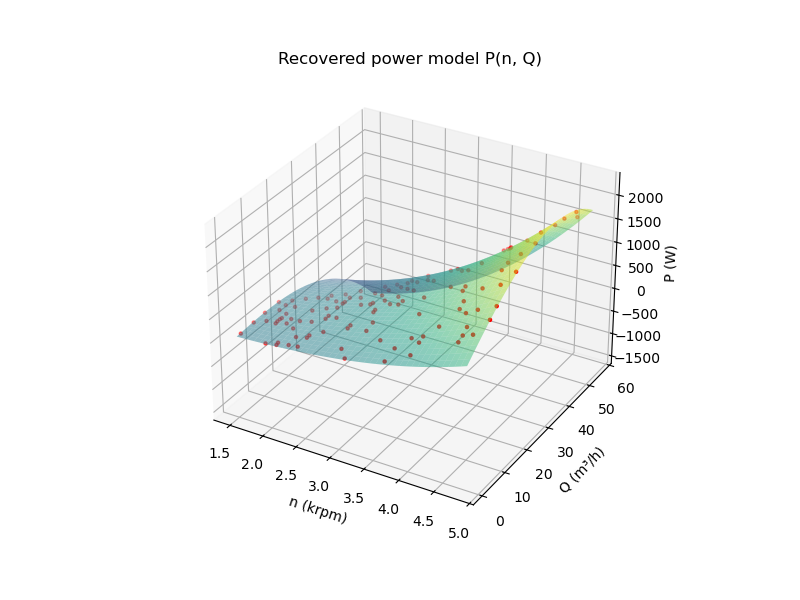

In [ ]:
n_vals = np.linspace(train["n"].min(), train["n"].max(), 40)
Q_vals = np.linspace(train["Q"].min(), train["Q"].max(), 40)
n_grid, Q_grid = np.meshgrid(n_vals, Q_vals)

grid = pd.DataFrame({"n": n_grid.ravel(), "Q": Q_grid.ravel()})
P_grid = final_model.predict(make_features(grid)[chosen_cols]).reshape(n_grid.shape)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(n_grid, Q_grid, P_grid, cmap="viridis", alpha=0.5)
ax.scatter(test["n"], test["Q"], test["P"], color="red", s=5)
ax.set_xlabel("n (krpm)")
ax.set_ylabel("Q (m³/h)")
ax.set_zlabel("P (W)")
ax.set_title("Recovered power model P(n, Q)")
plt.show()

In [ ]:
from scipy import stats

N = len(X_train)

full = LinearRegression()
full.fit(X_train[all_cols], y_train)
rss_f = full.rss(X_train[all_cols], y_train)
p_f = len(all_cols) + 1

f_results = []
for subset in all_subsets:
    if len(subset) == len(all_cols):          # the full model itself, nothing to test
        continue

    model = LinearRegression()
    model.fit(X_train[subset], y_train)
    rss_r = model.rss(X_train[subset], y_train)
    p_r = len(subset) + 1

    F = ((rss_r - rss_f) / (p_f - p_r)) / (rss_f / (N - p_f))
    p_value = stats.f.sf(F, p_f - p_r, N - p_f)

    f_results.append({"n_terms": len(subset), "features": tuple(subset),
                      "rss": rss_r, "F": F, "p_value": p_value})

f_results = pd.DataFrame(f_results)

In [ ]:
f_best_rows = []
for t in range(1, n_cols):
    models_with_t_terms = f_results[f_results["n_terms"] == t]
    f_best_rows.append(models_with_t_terms.sort_values("rss").iloc[0])
f_best = pd.DataFrame(f_best_rows).reset_index(drop=True)

print(f_best[["n_terms", "F", "p_value", "features"]].to_string())

alpha = 0.05
for i in range(len(f_best)):
    if f_best.iloc[i]["p_value"] > alpha:
        f_chosen = f_best.iloc[i]
        break
print("Chosen:", f_chosen["n_terms"], "terms:", f_chosen["features"])

    n_terms             F       p_value                                                                              features
0         1  10117.902385  0.000000e+00                                                                               (n3Q0,)
1         2   3926.074474  0.000000e+00                                                                          (n2Q2, n3Q1)
2         3      8.971355  1.474929e-15                                                                    (n0Q3, n2Q1, n3Q0)
3         4      1.045457  4.048072e-01                                                              (n0Q3, n1Q2, n2Q1, n3Q0)
4         5      1.071154  3.829302e-01                                                        (n0Q3, n1Q0, n1Q2, n2Q1, n3Q0)
5         6      0.883311  5.400302e-01                                                  (n0Q3, n1Q0, n1Q2, n2Q0, n2Q1, n3Q0)
6         7      0.821245  5.841038e-01                                            (n0Q3, n1Q2, n1Q3, n2Q1, n2Q3, n3Q0